# Ablation lab -- which rules carry the edge, which are drag?

**Cutting & isolating** (NotebookLM findings Part 4.1). Every strategy
scores named legs; this lab re-evaluates every leg subset over one
backtest and ranks by out-of-sample profit factor. A subset that beats
the full production set (marked `*`) with a healthy sample means the
missing legs are **drag, not edge** -- deletion candidates.

Two engines agree unless noted:
- `ablate.py` -- event-loop, re-scores leg pass-masks (exact engine logic)
- `ablate_vbt.py` -- vectorbt full-matrix (fast, every rule combination)

Set `STRATEGY` below and run all. Routed strategies (bollinger) **must**
be ablated inside their regime slot -- see the regime cell.

In [1]:
from pathlib import Path
import subprocess, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'config.json').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from rhengine import viz
from rhengine.costs import default_cost_bps
viz.use_style()
CFG = json.load(open(ROOT / 'config.json'))
RESULTS = ROOT / 'tests' / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)

# Full-market event-loop passes are slow; cap the universe for a live
# notebook run and raise it (or set 0) when you want the real number.
MAX_TICKERS  = 0    # 0 = full universe (was 150; full-market for real data density)
LOOKBACK     = 400
# Audit FC-2: resolved from config.json costs.round_trip_bps (30.0), not
# hardcoded. The old literal 5 is a mega-cap assumption; this universe
# floors at $500k/day and pooled breakeven is ~16 bps. Override per-run by
# assigning after this line, and say so when you report the number.
COST_BPS     = default_cost_bps(CFG)
REFRESH      = False   # True -> recompute cached CSVs even if present
print('root:', ROOT, '| data_source:', CFG.get('data_source'))

root: c:\Users\there\Downloads\ClaudeWork\AgentTradingLogic | data_source: massive


In [2]:
STRATEGY = 'residualmomentum'   # vwap|bollinger|macd|residualmomentum|pead|consolidation
REGIME   = None                 # e.g. 'choppy' for bollinger's routing slot
SPLIT    = 0.7

## 1 -- Run the event-loop ablation

`ablate.py` runs one backtest at the emission floor (score>=2), records
each trade's leg pass-mask, then qualifies every leg subset. Output is
PF-ranked by OOS.

In [3]:
cmd = [sys.executable, '-m', 'rhengine.ablate', '--strategy', STRATEGY,
       '--lookback-days', str(LOOKBACK), '--cost-bps', str(COST_BPS),
       '--split', str(SPLIT)]
if REGIME: cmd += ['--regime', REGIME]
print(subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True).stdout)

  Universe: 3309 of 13125 cached tickers pass filters (min_price=1.0, min_dollar_vol=500,000, excluded 5550 ETFs, excluded 997 ADR/biotech)
Fetching 3310 symbols, 400d of history (source=massive)...
  Massive: 285 days in window, 0 uncached (~0min to backfill at 5/min); using cache...
  Massive: 3310 ok, 0 empty

Ablation — residualmomentum | legs: RA-RES, EMA21, EMA CROSS, RSI | 150787 emitted trades | split 0.7 (2026-04-22) | 30.0 bps | legMask=1
  legMask 1 in effect: RA-RES must genuinely pass, EMA21+EMA CROSS+RSI bypassed into the score.
  Leg state is still recorded truthfully, so the subsets below are real.
  leg states: 1111 54.1%  1101 29.9%  1110 7.5%  1100 3.9%  1010 3.6%  1011 1.0%  (+1 more)

  active legs (ranked by OOS PF)  IS:     n   win%    avgR     PF      t   OOS:     n   win%    avgR     PF      t
  RA-RES                          IS: 101981  41.9%  -0.020   0.96   -5.2   OOS: 48806  41.6%  -0.026   0.95   -4.8
  RA-RES+RSI                      IS: 86319  41.8%  -0

## 2 -- Chart the leg subsets (in-code re-derivation)

We reproduce the subset table as data so we can chart it. This reuses the
exact `ablate.evaluate_masks` over a fresh capped-universe backtest.

In [4]:
from rhengine.ablate import evaluate_masks
from rhengine.backtest import run_backtest_on, _iso_date, WARMUP_BARS
from rhengine.indicators import load_spec
from rhengine.data_local import load_bars_any

bars_map, spy_bars = load_bars_any(CFG, lookback_days=LOOKBACK, verbose=False)
if MAX_TICKERS: bars_map = dict(list(bars_map.items())[:MAX_TICKERS])
leg_names = [l['abbr'] for l in load_spec()['strategies'][STRATEGY]['legs']]
dates = [_iso_date(b['time']) for b in spy_bars[WARMUP_BARS:]]
split_date = dates[int(len(dates) * SPLIT)]
trades = run_backtest_on(CFG, bars_map, spy_bars, min_score=2,
                         forced_strategy=STRATEGY, cost_bps=COST_BPS,
                         regime_only=REGIME)
rows = evaluate_masks(trades, len(leg_names), split_date)

def pf(st): return (np.nan if not st else 1e9 if st['profit_factor']==float('inf')
                    else st['profit_factor'])
tbl = pd.DataFrame([{ 'legs': '+'.join(leg_names[i] for i in a),
                      'is_n': (s and s['n']) or 0, 'oos_n': (o and o['n']) or 0,
                      'is_avgR': (s or {}).get('avg_r', np.nan),
                      'oos_avgR': (o or {}).get('avg_r', np.nan),
                      'oos_pf': pf(o), 'oos_t': (o or {}).get('t_stat', np.nan) }
                    for a, s, o in rows])
FULL = '+'.join(leg_names)
tbl = tbl.sort_values('oos_pf', ascending=False).reset_index(drop=True)
tbl

,legs,is_n,oos_n,is_avgR,oos_avgR,oos_pf,oos_t
0,RA-RES,101981,48806,-0.020080,-0.025580,0.949379,-4.796495
1,RA-RES+RSI,86319,41938,-0.024756,-0.027216,0.946197,-4.769382
2,RA-RES+EMA21+RSI,85370,41260,-0.026443,-0.030233,0.940486,-5.250429
3,RA-RES+EMA CROSS,65000,34706,-0.047112,-0.033195,0.934776,-5.260272
4,RA-RES+EMA CROSS+RSI,53878,29215,-0.050880,-0.037733,0.925973,-5.562765
5,RA-RES+EMA21,97691,46102,-0.028134,-0.038853,0.924387,-7.078466
6,RA-RES+EMA21+EMA CROSS+RSI,53022,28580,-0.054063,-0.042355,0.917411,-6.170051
7,RA-RES+EMA21+EMA CROSS,60803,32045,-0.061964,-0.052954,0.898443,-8.063528


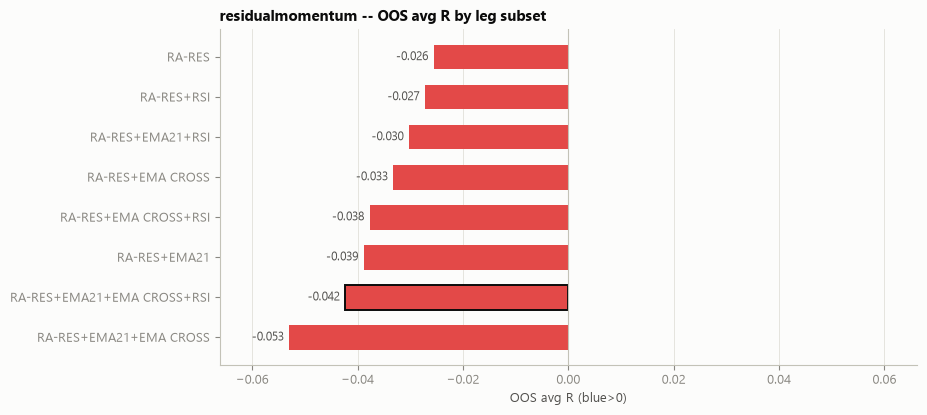

In [5]:
# OOS avg R per leg subset -- production set outlined. Anything above it
# with a real sample is a cut candidate.
sub = tbl[(tbl.is_n + tbl.oos_n) >= 100].copy()
fig, ax = viz.bars_signed(sub['legs'].tolist(), sub['oos_avgR'].tolist(),
        title=f'{STRATEGY}{" ["+REGIME+"]" if REGIME else ""} -- OOS avg R by leg subset',
        xlabel='OOS avg R (blue>0)', highlight=FULL)
plt.show()

## 3 -- IS vs OOS overfit scan

Subsets in the lower-right wedge win in-sample but lose out-of-sample --
that is curve fit, not edge. The production set should sit on or above
the diagonal.

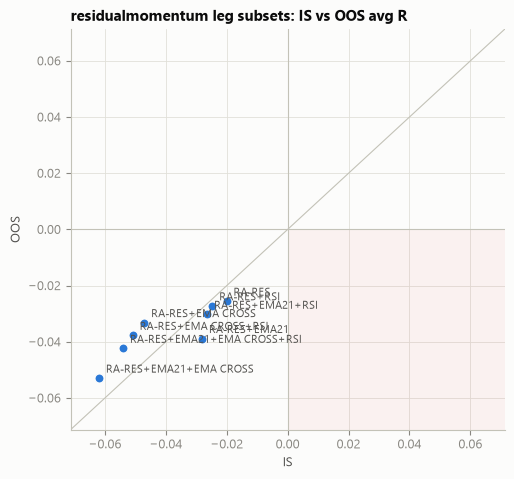

In [6]:
s2 = tbl.dropna(subset=['is_avgR', 'oos_avgR'])
fig, ax = viz.is_oos_scatter(s2['is_avgR'], s2['oos_avgR'],
        labels=s2['legs'], title=f'{STRATEGY} leg subsets: IS vs OOS avg R')
plt.show()

## 4 -- Cross-check against the vectorbt full-matrix

`ablation_vbt_results.csv` (committed) is the fast whole-market matrix.
If the two engines disagree on the winning subset, investigate before
trusting either -- this is exactly what happened with bollinger choppy.

In [7]:
vbt_csv = ROOT / 'ablation_vbt_results.csv'
if vbt_csv.exists():
    vbt = pd.read_csv(vbt_csv)
    v = vbt[vbt.strategy == STRATEGY].sort_values('oos_pf', ascending=False)
    display(v[['rules','n_rules','trades','oos_pf','is_pf','oos_trades']].head(12))
else:
    print('run: py -m rhengine.ablate_vbt  (writes ablation_vbt_results.csv)')

,rules,n_rules,trades,oos_pf,is_pf,oos_trades
25,EMA-X,1,47928,1.183542,1.154765,15696
68,EMA21,1,134550,1.145761,1.041686,46683
67,RSI-BAND,1,133006,1.132079,1.050805,47075
73,EMA21+RSI-BAND,2,138994,1.124173,1.045202,49182
74,EMA-X+RSI-BAND,2,95815,1.115716,1.027623,33803
64,RA-RES+EMA-X,2,84537,1.106280,1.072927,31231
47,RA-RES,1,131568,1.104868,1.123968,47136
77,EMA21+EMA-X+RSI-BAND,3,101214,1.100533,1.016318,35711
79,EMA21+EMA-X,2,92486,1.097078,1.008346,31826
51,RA-RES+RSI-BAND,2,102874,1.087090,1.108262,37478


---
**Read-off:** the top OOS-PF subset with >=300 total trades is the lean
configuration. If it drops legs the production set keeps, encode the cut
in `config.json` `legMask` and re-validate in the walk-forward lab before
promoting. Never promote on this table alone -- it is a single split.